# Copula aggregation, tail dependence and the Euler allocation

**Question:** At the same four marginals and the same correlation matrix, how much more capital does Banco Andino need when
its risks are tied by a Student t copula instead of a Gaussian one, and which risk carries the extra tail?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the simple sum and the square-root rule)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state what a copula is (Sklar's theorem), draw uniforms with the Gaussian and the Student t copula and say what tail
  dependence is, with the closed form of the t and Clayton coefficients;
- turn the four marginals of Banco Andino into a simulation of the four losses and read the VaR, expected shortfall and
  economic capital of their sum;
- see why the Student t copula asks for more capital than the Gaussian one at the same correlation, and by how much at each
  degree of freedom;
- allocate the expected shortfall of the total to the four risks with the Euler principle, check that the contributions
  add up exactly, and compare with the closed-form allocation of the square-root rule.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import euler
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import portfolio as port_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the same case as notebook 01, **C18** (Banco Andino).

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (`outputs.aggregation`: the marginals, the correlation matrix, the set of degrees of freedom, the committed band and the committed Euler allocation), `data/derived/C18/t-copula-baseline.json` (the same block with the market-credit correlation stress) and `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`: the quantile function of each of the four marginals on a named probability grid, contract `c18-models` 3.0.0).
- **How the committed rows were made.** The pipeline builds a sample of one million losses for each marginal with the engine (credit: the grouped copula of the C07 segments; market: a Student t fitted to the VaR and ES of C11; interest rate risk: the Hull-White simulation of C15; operational risk: the Fourier aggregation of the C17 generator), hands the four quantile functions to `dependence_band`, and commits the result. **The four samples are not committed, but each marginal's quantile function is**, on a named grid: the 1,961 probabilities $\Phi(z)$ for $z$ from -4.9 to 4.9 in steps of 0.005, dense in both tails. Step 3 rebuilds the four marginals from the grids by linear interpolation in the probability, the rule the aggregation applies to the sorted sample, and step 4 runs the pipeline's own aggregation on them with the pipeline's seed, so the committed rows are expected back almost to the digit. The committed rows are always printed beside the notebook's own.

In [2]:
# The baseline aggregation block and the committed quantile grids of the four marginals
agg = read_json("C18/baseline.json")["outputs"]["aggregation"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
marginals = agg["marginals"]
risks = [m["risk"] for m in marginals]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
LABEL = {"credit": "credit", "market": "market", "irrbb": "interest rate",
         "operational": "operational"}
names = [LABEL[r] for r in risks]

## Method

### Step 1: a copula and its tail dependence

**Sklar's theorem.** Any joint distribution of losses $L_1, \dots, L_d$ with marginal distribution functions $F_k$ can be written $F(x_1, \dots, x_d) = C(F_1(x_1), \dots, F_d(x_d))$, where the copula $C$ carries all the dependence and the $F_k$ carry all the marginal behaviour. Aggregation by copula therefore has three parts: choose the marginals, choose $C$, and simulate $L_k = F_k^{-1}(U_k)$ with $U \sim C$ (dossier 05, G.1 item 3; McNeil, Frey and Embrechts 2015, whose chapter number is UNVERIFIED in the dossier).

- **Gaussian copula** with correlation matrix $R$: $U = \Phi(Z)$ with $Z \sim N(0, R)$ (Li 2000). It has no tail dependence for $|\rho| < 1$: extremes of the two risks become independent far enough into the tail.
- **Student t copula** with $\nu$ degrees of freedom: $U = t_\nu(X)$ with $X = \sqrt{\nu / \chi^2_\nu}\, Z$ (Frey and McNeil 2003; Demarta and McNeil 2005). Its bivariate **tail dependence coefficient**, the limit of $P(U_2 > q \mid U_1 > q)$ as $q \to 1$, is
$$\lambda = 2\, t_{\nu+1}\!\left(-\sqrt{\frac{(\nu+1)(1-\rho)}{1+\rho}}\right).$$
- **Clayton copula** (bivariate): $C_\theta(u, v) = (u^{-\theta} + v^{-\theta} - 1)^{-1/\theta}$ with $\theta > 0$, and lower tail dependence $\lambda_L = 2^{-1/\theta}$. The engine has the closed forms of Clayton but does not sample it (the module's docstring defers Clayton sampling and vine copulas).

The next cell draws the tail dependence coefficient of the t copula against the correlation for each degree of freedom of
the case, marks the case's own correlation of 0.5, and prints the coefficient there next to the Clayton closed forms.

t, rho = 0.5, nu =    4:  0.2532
t, rho = 0.5, nu =    8:  0.1173
t, rho = 0.5, nu =   30:  0.003


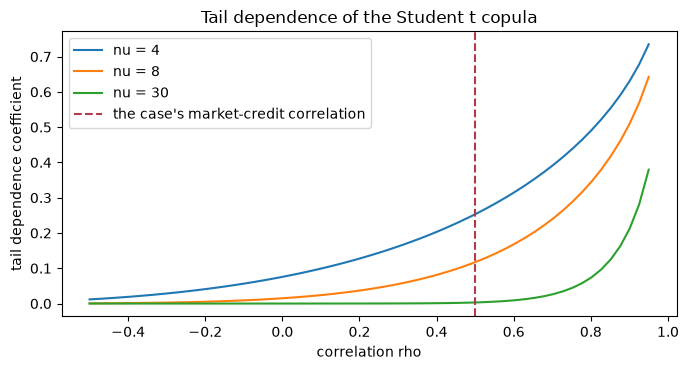

Clayton theta = 0.5: 0.25
Clayton theta = 1.0: 0.5
Clayton theta = 2.0: 0.7071


In [3]:
# The t tail dependence against the correlation for each nu of the case, and the Clayton closed forms
rho_grid = np.linspace(-0.5, 0.95, 60)
fig, ax = plt.subplots(figsize=(7, 3.8))
for nu in NU_SET:
    ax.plot(rho_grid, [cop.t_tail_dependence(r, nu) for r in rho_grid], label=f"nu = {nu:g}")
    print(f"t, rho = 0.5, nu = {nu:4.0f}: ", round(cop.t_tail_dependence(0.5, nu), 4))
ax.axvline(0.5, color="#b23a48", linestyle="--", label="the case's market-credit correlation")
ax.set_xlabel("correlation rho")
ax.set_ylabel("tail dependence coefficient")
ax.set_title("Tail dependence of the Student t copula")
ax.legend()
fig.tight_layout()
plt.show()
for theta in (0.5, 1.0, 2.0):
    print(f"Clayton theta = {theta}:", round(cop.clayton_lower_tail_dependence(theta), 4))

Each curve rises with the correlation and falls fast as the degrees of freedom grow: at the case's correlation of 0.5 the
coefficient is 0.2532 with four degrees of freedom, 0.1173 with eight and 0.0030 with thirty, which is why the case treats
a t copula with thirty degrees of freedom as a stand-in for the Gaussian one. A Gaussian copula would be a flat line at
zero. The Clayton numbers printed under the figure show the other way to get tail dependence, a single parameter that
loads only the lower tail; the engine has its closed forms but does not sample it, so it stays a formula here.

### Step 2: drawing uniforms and measuring the tail

`simulate_copula_uniforms(corr, family, nu, n, seed)` returns $n \times K$ uniforms with the copula of the matrix `corr`. Both families give the same rank correlation: the Kendall $\tau$ of a pair is $(2/\pi)\arcsin\rho$, 0.3333 for $\rho = 0.5$, so a rank statistic cannot tell the copulas apart. What differs is the corner.

The next cell draws one million pairs from each copula at the correlation 0.5 with `simulate_copula_uniforms`, counts the
joint exceedances at three levels and scatters four thousand pairs of each, with the corner at 0.99 marked.

Gaussian P(U2 > q given U1 > q) at q = 0.9, 0.99, 0.999 [0.3222 0.1278 0.0552]
t (nu=4) P(U2 > q given U1 > q) at q = 0.9, 0.99, 0.999 [0.3849 0.2816 0.2784]


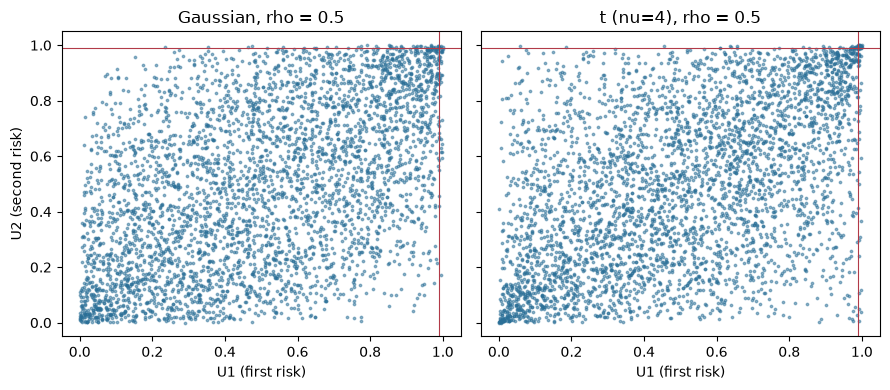

In [4]:
# Draw one million pairs from the Gaussian and the t(4) copula at rho = 0.5, count joint exceedances and scatter
pair = np.array([[1.0, 0.5], [0.5, 1.0]])
draws = {"Gaussian": cop.simulate_copula_uniforms(pair, "gaussian", None, 1_000_000, 7),
         "t (nu=4)": cop.simulate_copula_uniforms(pair, "t", 4.0, 1_000_000, 7)}
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, (name, u) in zip(axes, draws.items()):
    ax.scatter(u[:4000, 0], u[:4000, 1], s=3, alpha=0.5, color="#2a6f97")
    ax.axvline(0.99, color="#b23a48", linewidth=0.8)
    ax.axhline(0.99, color="#b23a48", linewidth=0.8)
    ax.set_title(f"{name}, rho = 0.5")
    ax.set_xlabel("U1 (first risk)")
    hits = [float((u[u[:, 0] > q, 1] > q).mean()) for q in (0.9, 0.99, 0.999)]
    print(name, "P(U2 > q given U1 > q) at q = 0.9, 0.99, 0.999", np.round(hits, 4))
axes[0].set_ylabel("U2 (second risk)")
fig.tight_layout()
plt.show()

The two clouds have the same centre and the same rank correlation, a Kendall tau of 0.3333 for a correlation of 0.5, so no
rank statistic tells them apart. What differs is the corner: the t copula puts visibly more points in the upper right and
lower left, which for losses is where both risks go wrong together. The counts say the same with numbers: given that the
first risk is above its 99.9 percent quantile, the second is too with probability 0.0552 under the Gaussian copula and
0.2784 under the t with four degrees of freedom, against a limit of 0.2532. With a million draws only about a thousand
pairs reach that corner, so the estimate is a picture of the limit, not a measurement of it.

### Step 3: the marginals

The copula needs a quantile function $F_k^{-1}$ for each risk, and the case commits them. For each marginal the models document holds its quantile at the probabilities $\Phi(z)$, $z = -4.9, -4.895, \dots, 4.9$ (1,961 points, in CLP millions), from about $5 \times 10^{-7}$ to $1 - 5 \times 10^{-7}$, the reach of the first and last of the $10^6$ draws. Between two points the quantile function is linear in the probability and clamped at the ends, which is the rule of the engine's `marginal_ppf_sample` applied to a sorted sample. Nothing is fitted: the shape of every marginal, the heavy tail of operational risk included, is the pipeline's.

The next cell rebuilds the four quantile functions by linear interpolation of the committed grids, reads a sample of $10^6$
Hazen positions from each and draws the four quantile functions against the standard normal score $z$ of the probability
level. The VaR and ES that the engine's estimators read from each sample are printed beside the committed ones.

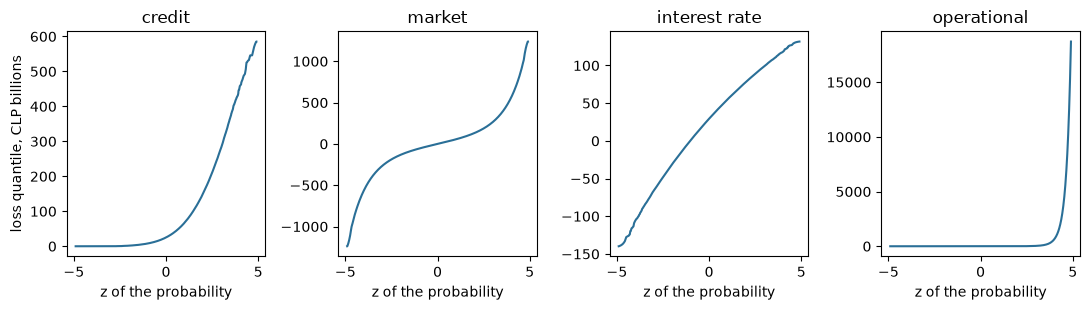

credit           VaR    298239 (   298227)  ES    346964 (   346949)
market           VaR    283436 (   283435)  ES    355807 (   355803)
interest rate    VaR    100747 (   100746)  ES    106381 (   106382)
operational      VaR     42357 (    42367)  ES    173668 (   171091)


In [5]:
# Rebuild the four marginals from the committed quantile grids and read their VaR and ES with the engine
LEVEL = 0.999
probs = np.array(grid["probabilities"])
positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, m, q in zip(axes, marginals, grid["marginals"]):
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(positions, probs, quantiles)
    ax.plot(stats.norm.ppf(probs), quantiles / 1e3, color="#2a6f97")
    ax.set_title(LABEL[m["risk"]])
    ax.set_xlabel("z of the probability")
axes[0].set_ylabel("loss quantile, CLP billions")
fig.tight_layout()
plt.show()
for m in marginals:
    var_here = rv_port.var_from_sample(samples[m["risk"]], LEVEL)
    es_here = rv_port.es_from_sample(samples[m["risk"]], LEVEL)
    row = (LABEL[m["risk"]], var_here, m["var_clp_m"], es_here, m["es_clp_m"])
    print("%-16s VaR %9.0f (%9.0f)  ES %9.0f (%9.0f)" % row)

Each panel is the loss that is not exceeded at a given probability, plotted against the normal score of that probability, so
a straight line would be a normal marginal. Credit curves smoothly, market risk is symmetric around zero, interest rate
risk is nearly linear and operational risk is flat for most of the range and then shoots up in the last tenth of the axis:
the heavy tail. Nothing is fitted in this notebook, the shapes are the case's own. The printed VaR matches the committed
one in brackets to within 0.03 percent, for instance 298,239 against 298,227 for credit, and the ES of operational risk
reads 173,668 against 171,091, 1.5 percent higher, because the committed figure comes from the severity grid and this one
from a sample of the interpolated grid.

### Step 4: simulate the four losses and aggregate

`simulate_component_losses(ppfs, corr, family, nu, n_draws, seed, chunk_size)` draws the uniforms of step 2 for the four risks and maps each through its quantile function, giving an $n \times 4$ matrix of losses $L_k = F_k^{-1}(U_k)$. The total of a scenario is the row sum. `copula_aggregate` does the same and returns the VaR, the ES and the economic capital $EC = \mathrm{VaR} - \sum_k \mathrm{EL}_k$ of the total, with their Monte Carlo standard errors (batch means).

The next cell simulates the four losses once with the Gaussian copula and prints the first scenarios beside their row sums,
then runs the five aggregations of the case with `copula_aggregate` and draws their economic capital beside the committed
band, with the simple sum and the square-root total as reference lines.

In [6]:
# One simulation row by row, then the aggregations of the case with the pipeline's own settings
SEED, CHUNK, N_DRAWS = 42, 100_000, 1_000_000
el_total = sum(m["el_clp_m"] for m in marginals)
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, N_DRAWS, SEED, CHUNK)
total = joint.sum(axis=1)
print("first three scenarios, CLP millions", np.round(joint[:3], 0).tolist())
print("their row sums", np.round(total[:3], 0).tolist())
keys = [("gaussian-copula", None)] + [("t-copula", nu) for nu in NU_SET]
here = {}
for key in keys:
    family = "gaussian" if key[1] is None else "t"
    here[key] = cop.copula_aggregate(ppfs, R, family, key[1], el_total, LEVEL, N_DRAWS, SEED, CHUNK)
    print(f"{key[0]:16s} nu={str(key[1]):5s} EC {here[key].ec:10,.0f}  se {here[key].var_se:7,.0f}")

first three scenarios, CLP millions [[34585.0, -40953.0, 41628.0, 1244.0], [1959.0, -141702.0, -6731.0, 376.0], [24746.0, -40887.0, 41590.0, 1070.0]]
their row sums [36504.0, -146098.0, 26518.0]
gaussian-copula  nu=None  EC    491,999  se   2,554
t-copula         nu=4.0   EC    552,369  se   3,430
t-copula         nu=8.0   EC    528,318  se   2,794
t-copula         nu=30.0  EC    499,133  se   3,281


The five capitals are now in `here`; the next cell draws them beside the committed band rows and prints how far each t row
sits above the Gaussian one.

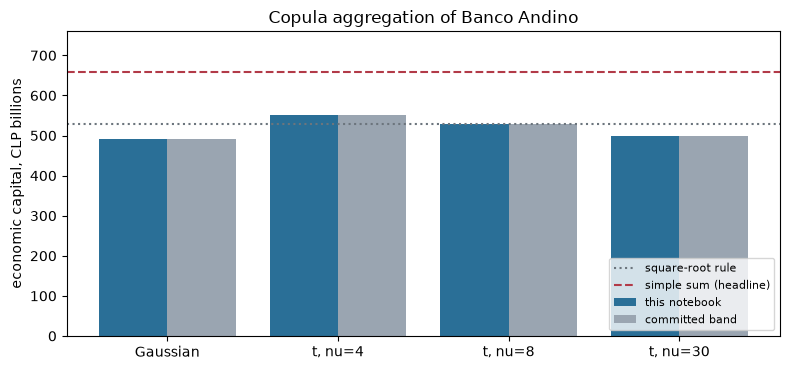

{'nu=4': 12.3, 'nu=8': 7.4, 'nu=30': 1.5}
above the Gaussian row, percent


In [7]:
# The five economic capitals beside the committed band rows, with the two closed-form totals as lines
labels = ["Gaussian" if k[1] is None else f"t, nu={k[1]:g}" for k in keys]
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [here[k].ec / 1e3 for k in keys], width=0.4, label="this notebook", color="#2a6f97")
baked = [committed[k]["capital_clp_m"] / 1e3 for k in keys]
ax.bar(x + 0.2, baked, width=0.4, label="committed band", color="#9aa5b1")
ax.axhline(simple.variance_covariance(np.array([m["ec_clp_m"] for m in marginals]), R) / 1e3, color="#6c757d",
           linestyle=":", label="square-root rule")
ax.axhline(agg["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--", label="simple sum (headline)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 760)
ax.set_ylabel("economic capital, CLP billions")
ax.set_title("Copula aggregation of Banco Andino")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
gaussian_ec = here[keys[0]].ec
print({f"nu={k[1]:g}": round((here[k].ec / gaussian_ec - 1) * 100, 1) for k in keys[1:]})
print("above the Gaussian row, percent")

The ordering is the one the theory predicts: the Gaussian copula at the bottom, then the t with thirty degrees of freedom,
then eight, then four. At the same marginals and the same correlation matrix, the fatter the tail dependence, the more
capital: the t rows lie 1.5, 7.4 and 12.3 percent above the Gaussian row, and all of them stay below the simple sum. Rebuilt
from the committed grids with the pipeline's seed, the four rows land on the committed ones to three decimals (491,999
against 491,974 for the Gaussian copula), differences far smaller than the Monte Carlo standard error of 2,554 to 3,430
printed in the previous cell. The figure shows the copula choice mattering by up to 12 percent of capital; it does not say
which copula is right, which is the question of notebook 07.

### Step 5: the Euler allocation of the expected shortfall

A total of $d$ risks can be split into $d$ contributions that add up to it. For a risk measure $\rho$ that is positively homogeneous of degree one, the **Euler contribution** of risk $k$ is the derivative of the total's measure when the size of risk $k$ grows, $\rho(L_k \mid L) = \frac{d}{dh}\rho(L + h L_k)\big|_{h=0}$, and the contributions add up to $\rho(L)$ (Tasche 2007, Definition 2.2 and Remark 2.1). For the expected shortfall the contribution is a conditional mean,

$$\mathrm{ES}_\alpha(L_k \mid L) = E\,[L_k \mid L \ge \mathrm{VaR}_\alpha(L)],$$

and the engine's `es_contributions` estimates it from the sample with the Acerbi-Tasche weights, so that the contributions add up to the sample ES exactly. The contribution of the VaR conditions on one point and is very noisy in simulation, which is why the case allocates the ES.

The next cell allocates the expected shortfall of the Gaussian aggregate of step 4 with `es_contributions`, runs the
engine's additivity test and draws each risk's share of the tail beside its share of the simple sum. The **Euler benefit**
of a risk is $1 - \mathrm{ES}(L_k \mid L)/\mathrm{ES}(L_k)$.

ES of the total 709403  0.0


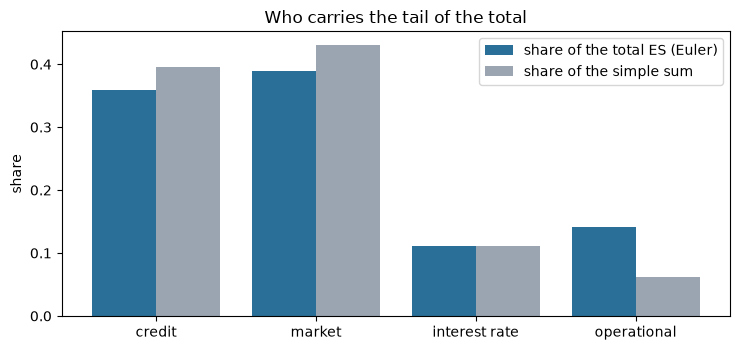

share of the tail {'credit': 0.359, 'market': 0.389, 'interest rate': 0.111, 'operational': 0.141}
percent, tail and simple sum [35.9 38.9 11.1 14.1] [39.6 43.1 11.1  6.3]
Euler benefit {'credit': 0.264, 'market': 0.225, 'interest rate': 0.263, 'operational': 0.458}


In [8]:
# Allocate the ES of the Gaussian aggregate, test additivity and draw each risk's share of the tail
es_total = rv_port.es_from_sample(total, LEVEL)
contributions = euler.es_contributions(joint, total, LEVEL)
additivity = port_tests.euler_additivity(contributions, es_total, 1e-6, model_id="notebook")
ec = np.array([m["ec_clp_m"] for m in marginals])
print("ES of the total", round(es_total), "", additivity.metric)
tail_share = contributions / es_total
sum_share = ec / ec.sum()
benefit = [simple.euler_diversification_benefit(contributions[k], rv_port.es_from_sample(joint[:, k], LEVEL))
           for k in range(len(risks))]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(np.arange(4) - 0.2, tail_share, width=0.4, color="#2a6f97", label="share of the total ES (Euler)")
ax.bar(np.arange(4) + 0.2, sum_share, width=0.4, color="#9aa5b1", label="share of the simple sum")
ax.set_xticks(np.arange(4))
ax.set_xticklabels(names)
ax.set_ylabel("share")
ax.set_title("Who carries the tail of the total")
ax.legend()
fig.tight_layout()
plt.show()
print("share of the tail", {k: round(float(v), 3) for k, v in zip(names, tail_share)})
print("percent, tail and simple sum", np.round(tail_share * 100, 1), np.round(sum_share * 100, 1))
print("Euler benefit", {k: round(float(v), 3) for k, v in zip(names, benefit)})

The allocation adds up to the total exactly, because the weights are built to, and what it reveals is where the tail lives.
Credit carries 35.9 percent of the total expected shortfall and market risk 38.9 percent, close to their shares of the simple
sum, but operational risk carries 14.1 percent of the tail against 6.3 percent of the simple sum: its marginal is heavy-tailed
(its expected shortfall is four times its VaR), so it matters more in the years that hurt. Its Euler benefit of 0.458 is
also the largest, since it is large only in years when the others are not. An allocation is only as good as the tails it was
computed on, and these are the committed ones.

**The closed-form allocation of the square-root rule.** For the variance-covariance total there is no simulation: with
$\Sigma_{jk} = R_{jk}\,EC_j\,EC_k$ the standard-deviation measure $\sqrt{\mathbf 1^{\top}\Sigma\,\mathbf 1}$ is homogeneous
and its Euler contributions are $(\Sigma\mathbf 1)_k / \sqrt{\mathbf 1^{\top}\Sigma\,\mathbf 1}$ (Tasche 2007, equation
3.4). The engine's `std_contributions` computes them, and the next cell allocates the square-root total of notebook 01 and
prints the Euler benefit of each risk.

In [9]:
# The closed-form Euler allocation of the square-root total and the benefit of each risk
sigma = R * np.outer(ec, ec)
std_parts = simple.std_contributions(sigma)
total_vc = simple.variance_covariance(ec, R)
print("square-root total", round(total_vc, 1))
print("sum of contributions", round(float(std_parts.sum()), 1))
for risk, part, own in zip(names, std_parts, ec):
    print(f"{risk:16s} {part:10,.0f} {own:10,.0f} {simple.euler_diversification_benefit(part, own):.3f}")

square-root total 528106.3
sum of contributions 528106.3
credit              220,570    260,607 0.154
market              246,017    283,435 0.132
interest rate        48,688     72,824 0.331
operational          12,831     41,179 0.688


## Results

Two allocations of the same four risks give two different pictures of who benefits. On the simulated tail of the Gaussian
copula the benefits are 0.264, 0.225, 0.263 and 0.458 for credit, market, interest rate and operational risk; on the
square-root rule they are 0.154, 0.132, 0.331 and 0.688, where the smaller the risk, the larger its benefit. The first
allocation reads the tail, the second reads a covariance, and a reader choosing an allocation is choosing a risk measure.

**Answer:** a Student t copula with four degrees of freedom asks for CLP 552,369 million at the case's marginals and
correlation, 12.3 percent more than the Gaussian copula's 491,999 million, with 7.4 percent more at eight degrees of freedom
and 1.5 percent at thirty; the extra tail is real because the t coefficient is 0.2532 at four degrees of freedom and the
Gaussian one is zero. The tail is carried above all by market risk (38.9 percent of the ES of 709,403 million) and credit
(35.9 percent), and operational risk carries 14.1 percent against 6.3 percent of the simple sum. The square-root allocation
adds up to 528,106 million.

What this notebook does not show: the million-draw samples behind the committed rows are not committed, so the marginals come
from a grid of 1,961 points and the rows agree to 0.01 percent and not to the last digit; the Clayton copula appears only in
closed form because the engine does not sample it; and every row is conditional on a correlation matrix that is a convention.

## Summary

- A copula separates the dependence from the marginals (Sklar); aggregation is: choose the marginals, choose the copula, simulate $L_k = F_k^{-1}(U_k)$ and read the VaR, ES and EC of the row sum.
- The Gaussian and the t copula share the same rank correlation but not the corner: the t has tail dependence $\lambda = 2\,t_{\nu+1}(\cdot)$, the Gaussian none, and a simulation shows the difference.
- The committed models document keeps each marginal's quantile function on a named grid, not the million losses; this notebook rebuilt the marginals from it and the committed rows came back to within 0.01 percent, in the committed order.
- The Euler allocation of the ES adds up to the total exactly and gives each risk a benefit; the square-root rule has a closed-form allocation that adds up too.

**What to try next.** Change the seed of step 4 and watch the capital move by about its standard error; then continue with notebook 03, which adds the two bounds that do not depend on any copula: the best and worst VaR over every dependence.

## References

- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. and Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, in Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Li, D. X. (2000), the Gaussian copula and Frey, R. and McNeil, A. J. (2003) and Demarta, S. and McNeil, A. J. (2005), the t copula, as cited by the engine's `riskvalidation.aggregation.copulas` module docstring.
- This repository: `docs/contracts/engine/aggregation-api.md`.